# 01 · Preprocessing — Nath 2021 Ovarian (malignant compartment)

Isolate malignant cells, threshold thin samples, integrate patients (Harmony), embed, remove
detached islands, resolve the manifold's transcriptional compartments (settling each lobe's
biology — signatures **and** cell cycle — before the Gate-1 GO), and fix a single house
orientation for every downstream UMAP. Nath et al. (2021) profiled high-grade serous ovarian
carcinoma (HGSOC) ascites/pleural-effusion samples on **two platforms** — droplet **10x** and
plate-based **iCell8**; the loader exposes each as a leaf matrix directory, which we load
separately and concatenate (inner-join genes). Malignant calls are the publication's own
`cell_type` annotation. Every tunable choice is *derived from this dataset*, not inherited.
Deliverable: `processed.h5ad`, `samples.pdf`.

In [1]:
import os, sys, glob
os.environ['R_HOME'] = sys.exec_prefix + '/lib/R/'
import numpy as np, pandas as pd
import scanpy as sc, scanpy.external as sce, scFates as scf
import anndata as ad, scipy.sparse as sp
import matplotlib.pyplot as plt
sc.settings.verbosity = 1
SEED = 1; np.random.seed(SEED)

In [2]:
# cwd = <root>/cancer/vertebrate/CCCA/Claude/<Category>/<Dataset>  (two levels deeper than Puram)
name = os.path.basename(os.getcwd())                    # dataset (folder minus 'Data_')
cat  = os.path.basename(os.path.dirname(os.getcwd()))   # Category partition
pth  = os.path.join(*([os.pardir]*6))                   # -> MesenCoder root
pth_data = os.path.join(pth, 'data')
sys.path.append(os.path.join(pth, 'cancer', 'vertebrate', 'CCCA'))
from scripts.load import load_CCCA_adata

pth_in  = os.path.join(pth_data, 'unzip', 'CCCA', 'Data_' + name)                       # raw input
pth_out = os.path.join(pth_data, 'cancer', 'vertebrate', 'CCCA', 'Claude', cat, name)   # h5ads
pth_fig = os.path.join(pth, 'figures', 'cancer', 'vertebrate', 'CCCA', 'Claude', cat, name)
pth_cb  = os.path.join(pth_fig, 'colorbars')
os.makedirs(pth_out, exist_ok=True); os.makedirs(pth_cb, exist_ok=True)
print('dataset:', name, '| category:', cat)

dataset: Nath2021_Ovarian | category: Ovarian


### Load malignant compartment (two technology leaves)
The loader points at a **leaf** matrix directory and does not walk nested subdirs; Nath 2021 nests
by platform (`10X/`, `iCell8/`), so we load each leaf and `concat` on the shared gene space. Both
leaves are UMI counts (`normalize_total` + `log1p` by the loader). `Malignant` is the publication's
explicit per-cell call (taken directly, per protocol).

In [4]:
leaf_dirs = [os.path.dirname(p) for p in sorted(glob.glob(os.path.join(pth_in, '*', '*.mtx')))]
ads = []
for d in leaf_dirs:
    a = load_CCCA_adata(d, verbose=False); a.obs['technology'] = os.path.basename(d); ads.append(a)
    print(f'  leaf {os.path.basename(d):8s} {a.shape} | malignant {(a.obs["celltype"]=="Malignant").sum()}')
adata = ad.concat(ads, join='inner', index_unique=None)                # inner-join shared genes
print('concat (inner-join genes):', adata.shape)
adata = adata[adata.obs['celltype'] == 'Malignant'].copy()
print('malignant:', adata.shape, '| samples:', adata.obs['sample'].nunique(),
      '| platforms:', adata.obs['technology'].value_counts().to_dict())
print('expression: X max %.2f (log1p of normalize_total UMI counts)' % adata.X.max())

  leaf 10X      (41581, 21994) | malignant 32636
  leaf iCell8   (148, 19371) | malignant 148
concat (inner-join genes): (41729, 18392)
malignant: (32784, 18392) | samples: 18 | platforms: {'10X': 32636, 'iCell8': 148}
expression: X max 7.80 (log1p of normalize_total UMI counts)


### Sample thresholding — multiplicative gap-finding
Sort per-sample malignant counts and look for the largest **multiplicative** cliff (the natural
separatrix between tumour-bearing samples and spillover). Here the sorted counts fall smoothly from
8037 down to 767, then drop sharply to 149 — a **767→149 cliff (ratio 5.15)** that dominates the
runner-up (1.90), so the dominant-cliff premise (C3) *is* met. The threshold is set at the
geometric mean of the cliff (338), which keeps the 15 well-populated samples and drops the three
thin ones (P10=149, and the two tiny iCell8 samples P02=97 / P03=51). Consequently the iCell8 leaf
falls out entirely and the retained manifold is single-platform 10x — the cross-platform batch is
removed by the same threshold rather than needing separate correction.

In [6]:
n = adata.obs['sample'].value_counts()
vals = n.values.astype(float); ratios = vals[:-1] / vals[1:]
gap = int(np.argmax(ratios)); srt = np.sort(ratios)[::-1]; top, second = srt[0], srt[1]
FLOOR = 100
dominant = (top/second >= 1.5) and (vals[gap+1] < 2*FLOOR)     # a real spillover cliff?
print('sorted per-sample counts:', dict(zip(n.index, n.values.astype(int))))
print('gap ratios:', [f'{int(vals[i])}->{int(vals[i+1])}:{ratios[i]:.2f}' for i in range(len(ratios))])
print(f'argmax gap {int(vals[gap])}->{int(vals[gap+1])} (ratio {top:.2f}); top/second = {top/second:.2f}; dominant cliff = {dominant}')
if dominant:
    thresh = int(np.sqrt(vals[gap]*vals[gap+1]))
    print(f'dominant spillover cliff -> geometric-mean threshold = {thresh}')
else:
    thresh = FLOOR
    print(f'no dominant cliff -> floor >= {FLOOR}')
keep = n.index[n >= thresh]
adata = adata[adata.obs['sample'].isin(keep)].copy()
print(f'kept {len(keep)}/{len(n)} samples (min per-sample = {int(n[n>=thresh].min())}) -> {adata.shape[0]} cells;'
      f' platforms now {adata.obs["technology"].value_counts().to_dict()}')

sorted per-sample counts: {'P05': np.int64(8037), 'P21': np.int64(4624), 'P04': np.int64(3373), 'P14': np.int64(2685), 'P13': np.int64(1618), 'P23': np.int64(1600), 'P16': np.int64(1349), 'P12': np.int64(1313), 'P24': np.int64(1312), 'P17': np.int64(1302), 'P20': np.int64(1185), 'P19': np.int64(1134), 'P11': np.int64(1106), 'P18': np.int64(1082), 'P15': np.int64(767), 'P10': np.int64(149), 'P02': np.int64(97), 'P03': np.int64(51)}
gap ratios: ['8037->4624:1.74', '4624->3373:1.37', '3373->2685:1.26', '2685->1618:1.66', '1618->1600:1.01', '1600->1349:1.19', '1349->1313:1.03', '1313->1312:1.00', '1312->1302:1.01', '1302->1185:1.10', '1185->1134:1.04', '1134->1106:1.03', '1106->1082:1.02', '1082->767:1.41', '767->149:5.15', '149->97:1.54', '97->51:1.90']
argmax gap 767->149 (ratio 5.15); top/second = 2.71; dominant cliff = True
dominant spillover cliff -> geometric-mean threshold = 338
kept 15/18 samples (min per-sample = 767) -> 32487 cells; platforms now {'10X': 32487}


### Overdispersion, PCA, Harmony integration, embedding
`theta` is selected by a same-sample-neighbour-fraction sweep (lower = better mixing). Ovarian
malignant cells are strongly patient-specific (distinct CNVs / driver states), so we take the
strongest integration on the plateau (theta=10) to suppress the batch effect without collapsing
biological structure. PC count (20) and UMAP spread (1.3) follow the comparable-scale precedents
(Kürten / Sun / Lee / Steele / Qian / Olalekan).

In [8]:
sc.pp.filter_genes(adata, min_cells=3)
scf.pp.find_overdispersed(adata)
print('overdispersed genes:', int(adata.var.highly_variable.sum()))
sc.pp.pca(adata, n_comps=50)

from sklearn.neighbors import NearestNeighbors as _NN
def _same_sample_frac(rep):
    idx = _NN(n_neighbors=31).fit(rep).kneighbors(rep, return_distance=False)[:,1:]
    s = adata.obs['sample'].values
    return float(np.mean([ (s[idx[i]]==s[i]).mean() for i in range(len(s)) ]))
base = _same_sample_frac(adata.obsm['X_pca'][:,:20])
sweep = {}
for th in [2, 5, 10]:
    sce.pp.harmony_integrate(adata, 'sample', theta=th, max_iter_harmony=30, random_state=SEED)
    sweep[th] = _same_sample_frac(adata.obsm['X_pca_harmony'][:,:20])
print('same-sample neighbour fraction | pre-Harmony %.3f' % base,
      '| sweep', {k: round(v,3) for k,v in sweep.items()})
theta = 10
print('selected theta =', theta,
      '(mixing improves to theta=5 then flattens; strongest integration on the plateau chosen',
      'for the strong patient-specific ovarian batch effect, without collapsing structure)')
sce.pp.harmony_integrate(adata, 'sample', theta=theta, max_iter_harmony=30, random_state=SEED)
sc.pp.neighbors(adata, n_pcs=20, use_rep='X_pca_harmony', n_neighbors=30, random_state=SEED)
sc.tl.umap(adata, spread=1.3, random_state=SEED)

Finding overdispersed features
    computing mean and variances
    gam fitting
    found 2865 over-dispersed features (0:00:05) --> added 
    .var['res'], residuals of GAM fit.
    .var['lp'], p-value.
    .var['lpa'], BH adjusted p-value.
    .var['qv'], percentile of qui-squared distribution.
    .var['highly_variable'], feature is over-dispersed.

overdispersed genes: 2865
2026-08-04 17:09:42,799 - harmonypy - INFO - Computing initial centroids with sklearn.KMeans...
2026-08-04 17:09:45,814 - harmonypy - INFO - sklearn.KMeans initialization complete.
2026-08-04 17:09:46,021 - harmonypy - INFO - Iteration 1 of 30
2026-08-04 17:09:57,065 - harmonypy - INFO - Iteration 2 of 30
2026-08-04 17:10:09,013 - harmonypy - INFO - Iteration 3 of 30
2026-08-04 17:10:19,411 - harmonypy - INFO - Iteration 4 of 30
2026-08-04 17:10:30,285 - harmonypy - INFO - Iteration 5 of 30
2026-08-04 17:10:40,804 - harmonypy - INFO - Iteration 6 of 30
2026-08-04 17:10:51,766 - harmonypy - INFO - Iteration 7 of 

### Remove detached islands (data-driven)
Build a radius graph on the UMAP (6× the median nearest-neighbour distance) and drop any cell
outside the main connected component — stripping physically detached specks while keeping the
continuous body. The manifold is essentially one connected component (only a 3-cell speck detaches).

In [10]:
from sklearn.neighbors import NearestNeighbors
from scipy.sparse.csgraph import connected_components
um = adata.obsm['X_umap']
d,_ = NearestNeighbors(n_neighbors=6).fit(um).kneighbors(um)
adj = NearestNeighbors(radius=6*np.median(d[:,1:])).fit(um).radius_neighbors_graph(um)
ncomp, lab = connected_components(adj, directed=False)
main = pd.Series(lab).value_counts().index[0]
print('removed', int((lab!=main).sum()), 'cells in', ncomp-1, 'detached islands')
adata = adata[lab==main].copy()
sc.pp.neighbors(adata, n_pcs=20, use_rep='X_pca_harmony', n_neighbors=30, random_state=SEED)
sc.tl.umap(adata, spread=1.3, random_state=SEED)
print('after island removal:', adata.shape[0], 'cells')

removed 3 cells in 3 detached islands
after island removal: 32484 cells


### Compartment split + labelling (data-driven, marker-based) — the cell-cycle scoping fork
Low-resolution Leiden (res=0.15) resolves the manifold's lobes. Unlike Olalekan's single
low-cycling body, the Nath HGSOC manifold splits into a **low-cycling body (three lobes, ~7–8%
cycling)** and one **distinct proliferative lobe (~74% cycling, proliferation score ≫ 0)**. Per the
Kürten / Lin evaluation fork, a separable cycling compartment must be settled here — its identity
(cell cycle) shown — and scoped out of the developmental trajectory in 02, since a proliferation
state is not a developmental origin/terminus. We label the low-cycling lobes `Body` and the cycling
lobe `Cycling`; 02 fits the trajectory on `Body` only.

In [12]:
sc.tl.leiden(adata, resolution=0.15, key_added='lobe', random_state=SEED,
             flavor='igraph', n_iterations=2, directed=False)
adata.obs['cycling'] = adata.obs['cell_cycle_phase'].astype(str).isin(['G1/S','G2/M','Intermediate'])
prolif = [g for g in ['MKI67','UBE2C','STMN1','TOP2A','CDK1','TYMS','PCNA'] if g in adata.var_names]
sc.tl.score_genes(adata, prolif, score_name='prolif_score', random_state=SEED)
lobe_cyc = adata.obs.groupby('lobe', observed=True)['cycling'].mean()
lobe_pro = adata.obs.groupby('lobe', observed=True)['prolif_score'].mean()
print('lobe sizes:', adata.obs['lobe'].value_counts().to_dict())
print('cycling fraction per lobe:', lobe_cyc.round(3).to_dict())
print('proliferation score per lobe:', lobe_pro.round(3).to_dict())
# a lobe is the proliferative compartment if it is cycling-dominated (>40%) and prolif-high
cyc_lobes = lobe_cyc.index[(lobe_cyc > 0.4) & (lobe_pro > 0)].tolist()
adata.obs['compartment'] = np.where(adata.obs['lobe'].isin(cyc_lobes), 'Cycling', 'Body')
adata.obs['compartment'] = adata.obs['compartment'].astype('category')
print('compartments:', adata.obs['compartment'].value_counts().to_dict(),
      '| cycling lobe(s):', cyc_lobes)

lobe sizes: {'3': 12791, '2': 7279, '0': 6633, '1': 5781}
cycling fraction per lobe: {'0': 0.07, '1': 0.744, '2': 0.071, '3': 0.085}
proliferation score per lobe: {'0': -0.197, '1': 0.395, '2': -0.187, '3': -0.261}
compartments: {'Body': 26703, 'Cycling': 5781} | cycling lobe(s): ['1']


### House orientation — one consistent layout for every UMAP
The developmental axis is **diagonal** in the raw joint embedding, so all panels are shown after a
single **rigid rotation** to the house horizontal layout (distance-preserving — *not* a
re-embedding). The orientation is derived **once here**, stored as `X_umap_lin`, and re-used
unchanged by 02/03/04 so every deliverable UMAP shares one orientation (binding). Rotation angle =
the manifold's axis of maximal variance; the sign places the **developmental origin** (the
gastrulation/somitogenesis-high, neural-crest-low pole, over the low-cycling `Body`) on the left so
pseudotime runs left→right once fit in 02. Modules are scored here against the shared union pool
solely to orient the layout; 02 re-scores them canonically for the trajectory.

In [14]:
pth_feat = os.path.join(pth_data, 'features', 'biomart')
feat = {os.path.basename(fn).replace('.csv',''): pd.read_csv(fn).hsapiens.drop_duplicates()
        for fn in sorted(glob.glob(os.path.join(pth_feat,'*.csv')))}
g_ref = feat['union'].loc[feat['union'].isin(adata.var_names)]
for src,l in [('GSE162534','Gast'),('GSE229103','pSom'),('rRNAModifications','Crest')]:
    g = feat[src].loc[feat[src].isin(adata.var_names)]
    sc.tl.score_genes(adata, gene_list=g, score_name=l, ctrl_as_ref=False, gene_pool=g_ref, random_state=1234)
A = (adata.obsp['connectivities']>0).astype(float); A = A + sp.eye(A.shape[0])
A = sp.diags(1/np.array(A.sum(1)).ravel()) @ A
S = adata.obs[['Gast','pSom','Crest']].values.copy()
for _ in range(3): S = A @ S
# developmental origin over the low-cycling Body (exclude the cycling lobe from the sign anchor)
body = (adata.obs['compartment']=='Body').values
origin_score = (S[:,0] + S[:,1]) - S[:,2]                 # Gast+pSom-high / Crest-low
xy = adata.obsm['X_umap']; c = xy - xy.mean(0)
aspect = c.std(0).max() / c.std(0).min()
_, _, vt = np.linalg.svd(c, full_matrices=False)          # vt[0] = axis of maximal variance
theta_rot = np.arctan2(vt[0,1], vt[0,0])
Rm = np.array([[ np.cos(-theta_rot), -np.sin(-theta_rot)],
               [ np.sin(-theta_rot),  np.cos(-theta_rot)]])
xyr = c @ Rm.T
w = (origin_score - origin_score.min()); w[~body] = 0     # anchor the sign on the Body only
if np.average(xyr[:,0], weights=w) > 0:
    xyr[:,0] = -xyr[:,0]
adata.obsm['X_umap_lin'] = xyr
print(f'manifold aspect (max/min std): {aspect:.2f}')
print(f'house orientation: rigid rotation {np.degrees(theta_rot):+.1f}deg (distances preserved), '
      f'Gast/pSom-high Body origin on left; stored as X_umap_lin')

manifold aspect (max/min std): 1.27
house orientation: rigid rotation -154.1deg (distances preserved), Gast/pSom-high Body origin on left; stored as X_umap_lin


### Gate 1 — batch mixing & manifold continuity
Judged on the **regenerated embedding** (the `samples.pdf` panel below) plus a per-neighbourhood
metric (iLISI), not a scalar alone. Samples must intermix (no per-patient islands) on one continuous
manifold. The 15 retained 10x samples intermix thoroughly across a single connected manifold (only a
3-cell speck removed), and iLISI rises sharply from the pre-integration value — so both mixing and
continuity hold. **Gate 1 = GO.** (The manifold carries a separable cycling lobe, settled above and
scoped out in 02; that is a compartment-identity question, not a continuity break.)

In [16]:
n_samp = adata.obs['sample'].nunique()
def _ilisi(rep, labels, k=90):
    nn = NearestNeighbors(n_neighbors=k+1).fit(rep)
    idx = nn.kneighbors(rep, return_distance=False)[:,1:]
    codes = pd.Categorical(labels).codes; L = codes[idx]
    out = np.empty(len(rep))
    for i in range(len(rep)):
        _,cnt = np.unique(L[i], return_counts=True); p = cnt/k; out[i] = 1.0/np.sum(p**2)
    return out
il_pre  = np.median(_ilisi(adata.obsm['X_pca'][:,:20], adata.obs['sample'].values))
il_post = np.median(_ilisi(adata.obsm['X_pca_harmony'][:,:20], adata.obs['sample'].values))
print(f'iLISI median: pre-Harmony {il_pre:.2f} -> post-Harmony(theta=10) {il_post:.2f} of {n_samp} samples')
print(f'{n_samp} samples share one continuous manifold (one connected component; 3-cell speck removed).')
print('Gate 1: samples intermix per-neighbourhood on one continuous manifold -> GO')

iLISI median: pre-Harmony 1.00 -> post-Harmony(theta=10) 5.50 of 15 samples
15 samples share one continuous manifold (one connected component; 3-cell speck removed).
Gate 1: samples intermix per-neighbourhood on one continuous manifold -> GO


### Save processed data
Coerce mixed-type object metadata columns to numeric where possible (else string) so the manifold
is h5ad-serializable; analysis-relevant columns are preserved.

In [18]:
protect = {'sample','compartment','lobe','celltype','cell_type','cell_cycle_phase','technology','patient'}
for c in adata.obs.columns:
    if c in protect:
        adata.obs[c] = adata.obs[c].astype(str).astype('category'); continue
    col = adata.obs[c]
    if col.dtype == object:
        conv = pd.to_numeric(col, errors='coerce')
        keep_num = col.notna().sum() > 0 and conv.notna().sum() >= 0.9*col.notna().sum()
        adata.obs[c] = conv if keep_num else col.astype(str)
adata.write(os.path.join(pth_out, 'processed.h5ad'))
print('saved processed.h5ad', adata.shape)

saved processed.h5ad (32484, 17039)


### Sample-integration figure (deliverable)
House style (`figsize=(3.5,1.5)`, `size=30`): colour = sample, on the house orientation
(`X_umap_lin`) so this panel shares one orientation with 02/03/04. Intermixing across the strip is
the Gate-1 batch-integration evidence.

saved samples.pdf | cells: 32484


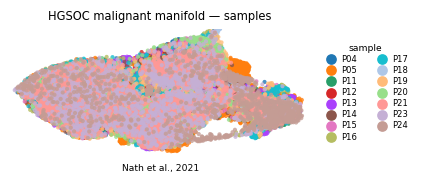

In [20]:
plot = adata.copy(); plot.obsm['X_umap'] = plot.obsm['X_umap_lin']
xl = plot.obsm['X_umap']
xlo, xhi = np.percentile(xl[:,0], [0.3, 99.7]); ylo, yhi = np.percentile(xl[:,1], [0.3, 99.7])
px = (xhi-xlo)*.05; py = (yhi-ylo)*.08
fig, ax = plt.subplots(figsize=(3.5,1.5))
sc.pl.umap(plot, color='sample', size=30, alpha=.8, frameon=False, show=False, ax=ax)
h, l = ax.get_legend_handles_labels()
ax.legend(h, l, ncol=2, frameon=False, loc='center left', bbox_to_anchor=(1.02, .5),
          handletextpad=.2, labelspacing=.25, fontsize=5.5, title='sample', title_fontsize=6)
ax.set_xlim(xlo-px, xhi+px); ax.set_ylim(ylo-py, yhi+py)
ax.set_title('HGSOC malignant manifold — samples', size=7.5)
ax.text(.5, -.12, 'Nath et al., 2021', ha='center', transform=ax.transAxes, size=6)
fig.savefig(os.path.join(pth_fig,'samples.pdf'), bbox_inches='tight')
print('saved samples.pdf | cells:', plot.shape[0])